In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

Resim başarıyla yüklendi!
Sinüs ve kosinüs değerleri hesaplandı!
Kenar piksel sayısı: 27291
Oylama işlemi tamamlandı!
Oylama matrisi kaydedildi!
Bulunan doğru sayısı: 20


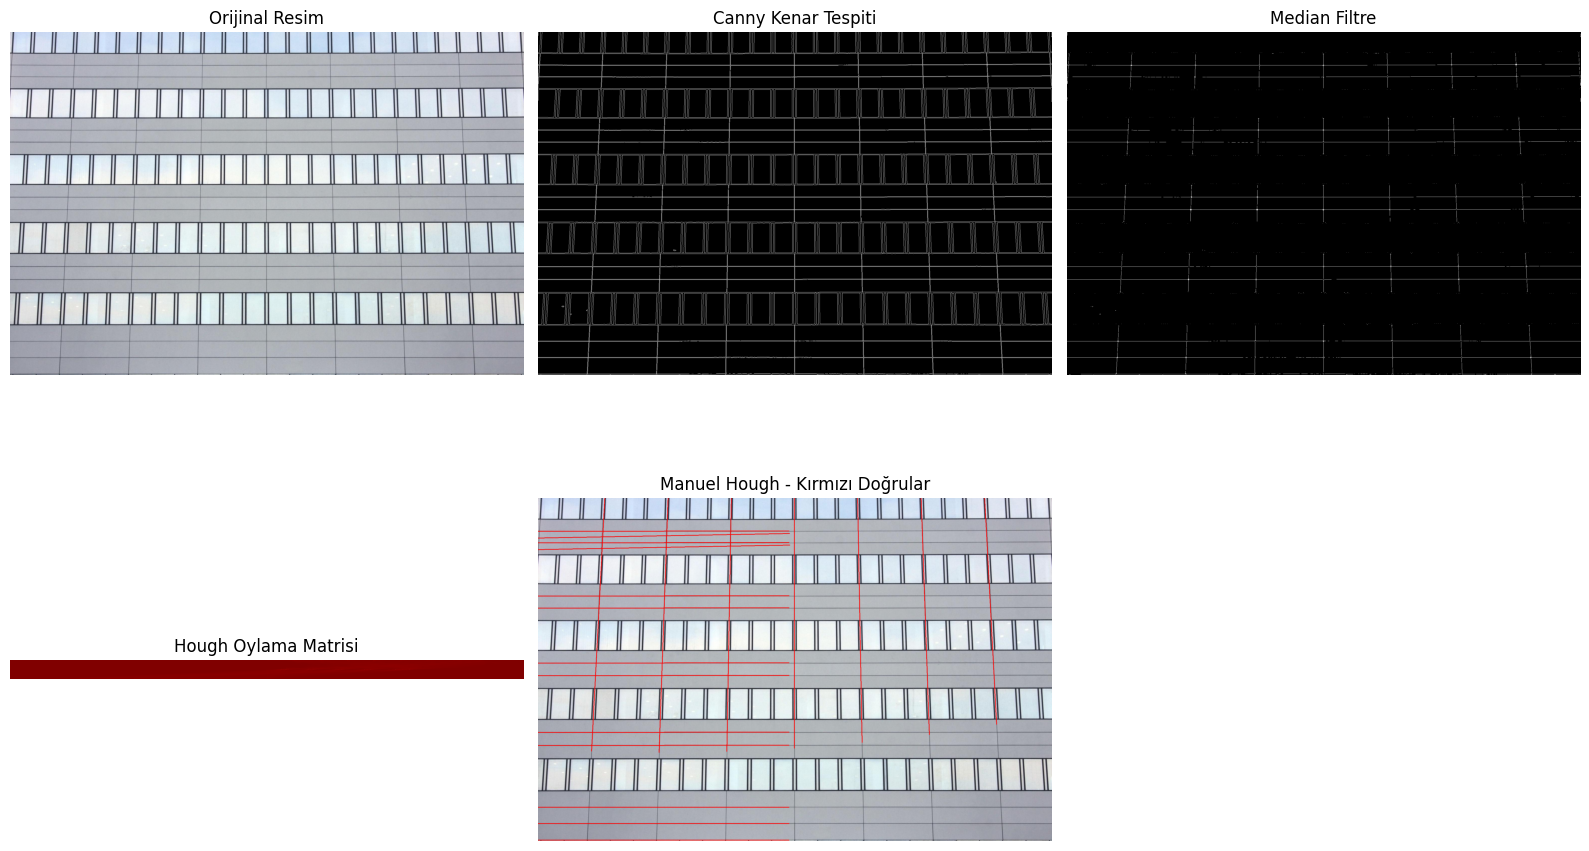

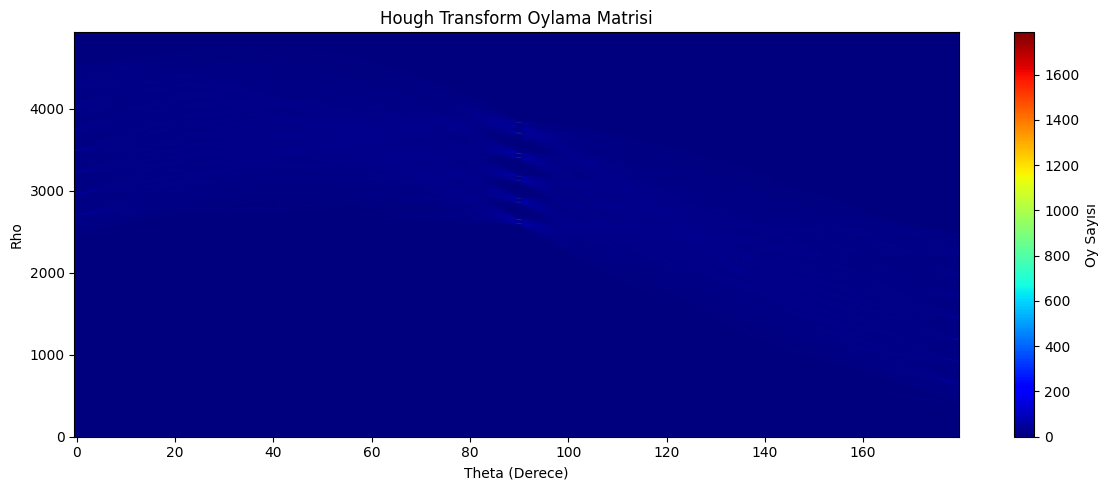

Kenar piksel sayısı: 27291
Bulunan doğru sayısı: 20
Oylama matrisi: /content/oylama_matrisi.png
Sonuç resmi: /content/manuel_hough_sonuc.png


In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# 1. RESMİ OKU
# ==========================================

resim_yolu = "/content/resim.jpg.avif"

img = cv2.imread(resim_yolu)

if img is None:
    pil_img = Image.open(resim_yolu).convert("RGB")
    img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

print("Resim başarıyla yüklendi!")

# ==========================================
# 2. GRİ TONLAMA VE CANNY
# ==========================================

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 50, 150)

# Median filtre
median = cv2.medianBlur(edges, 3)

# ==========================================
# 3. SIN VE COS DEĞERLERİNİ HESAPLA
# ==========================================

theta_degrees = np.arange(180)
theta_radians = np.deg2rad(theta_degrees)

# Sinüs ve kosinüs değerlerini önceden hesapla
cos_values = np.cos(theta_radians)
sin_values = np.sin(theta_radians)

print("Sinüs ve kosinüs değerleri hesaplandı!")

# ==========================================
# 4. OYLAMA MATRİSİNİ OLUŞTUR
# ==========================================

height, width = median.shape

rho_max = int(np.ceil(np.sqrt(height**2 + width**2)))

# Hata almamak için veri tipini np.float32 olarak ayarlıyoruz
accumulator = np.zeros(
    (2 * rho_max + 1, 180),
    dtype=np.float32
)

# Kenar piksellerini bul
y_indices, x_indices = np.nonzero(median)

print("Kenar piksel sayısı:", len(x_indices))

# ==========================================
# 5. OYLAMA İŞLEMİ
# ==========================================

chunk_size = 5000

for start in range(0, len(x_indices), chunk_size):

    end = min(start + chunk_size, len(x_indices))

    x = x_indices[start:end, None]
    y = y_indices[start:end, None]

    # rho = x*cos(theta) + y*sin(theta)
    rho_values = (
        x * cos_values[None, :]
        + y * sin_values[None, :]
    )

    rho_indices = np.round(rho_values).astype(int) + rho_max

    theta_indices = np.broadcast_to(
        np.arange(180),
        rho_indices.shape
    )

    # Oyları matrise ekle
    np.add.at(
        accumulator,
        (rho_indices.ravel(), theta_indices.ravel()),
        1
    )

print("Oylama işlemi tamamlandı!")

# ==========================================
# 6. OYLAMA MATRİSİNİ KAYDET
# ==========================================

accumulator_image = cv2.normalize(
    accumulator,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

accumulator_color = cv2.applyColorMap(
    accumulator_image,
    cv2.COLORMAP_JET
)

# Sadece yükseklik ve genişliği transpoze ediyoruz, renk kanalını (2) koruyoruz
accumulator_display = np.transpose(accumulator_color, (1, 0, 2))

cv2.imwrite(
    "/content/oylama_matrisi.png",
    accumulator_display
)

print("Oylama matrisi kaydedildi!")

# ==========================================
# 7. EŞİK DEĞERİNE GÖRE DOĞRULARI BUL
# ==========================================

threshold = 100

kernel = np.ones((11, 11), np.uint8)

dilated = cv2.dilate(accumulator, kernel)

peak_indices = np.argwhere(
    (accumulator >= threshold) &
    (accumulator == dilated)
)

peak_values = accumulator[
    peak_indices[:, 0],
    peak_indices[:, 1]
]

order = np.argsort(peak_values)[::-1]

selected_lines = []

for index in order:

    rho_index, theta_index = peak_indices[index]

    rho = rho_index - rho_max
    theta = theta_radians[theta_index]

    similar = False

    for old_rho, old_theta in selected_lines:

        if (abs(rho - old_rho) < 10 and
            abs(theta - old_theta) < np.deg2rad(6)):
            similar = True
            break

    if not similar:
        selected_lines.append((rho, theta))

    if len(selected_lines) == 20:
        break

print("Bulunan doğru sayısı:", len(selected_lines))

# ==========================================
# 8. DOĞRULARI ORİJİNAL RESME ÇİZ
# ==========================================

result = img.copy()

for rho, theta in selected_lines:

    a = np.cos(theta)
    b = np.sin(theta)

    x0 = a * rho
    y0 = b * rho

    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * a)

    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * a)

    cv2.line(
        result,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

cv2.imwrite(
    "/content/manuel_hough_sonuc.png",
    result
)

# ==========================================
# 9. SONUÇLARI GÖSTER
# ==========================================

plt.figure(figsize=(16, 10))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Kenar Tespiti")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(median, cmap="gray")
plt.title("Median Filtre")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(accumulator_display)
plt.title("Hough Oylama Matrisi")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Manuel Hough - Kırmızı Doğrular")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 10. OYLAMA MATRİSİNİ AYRICA BÜYÜK GÖSTER
# ==========================================

plt.figure(figsize=(12, 5))

plt.imshow(
    accumulator,
    cmap="jet",
    aspect="auto",
    origin="lower"
)

plt.title("Hough Transform Oylama Matrisi")
plt.xlabel("Theta (Derece)")
plt.ylabel("Rho")
plt.colorbar(label="Oy Sayısı")
plt.tight_layout()
plt.show()

# ==========================================
# 11. BİLGİLER
# ==========================================

print("Kenar piksel sayısı:", len(x_indices))
print("Bulunan doğru sayısı:", len(selected_lines))

print("Oylama matrisi: /content/oylama_matrisi.png")
print("Sonuç resmi: /content/manuel_hough_sonuc.png")